In [1]:
import warnings
import logging
import pyodbc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

INITIAL_TRAIN_WEEKS = 52
HORIZON_WEEKS = 2
EXCLUDE_LAST_WEEK = True
SEASONAL_PERIOD = 4  # Four-week cycle to test, NOT calendar-month seasonality.

logging.getLogger('cmdstanpy').setLevel(logging.WARNING)

## 1. Read weekly global sales from SQL

In [2]:
conn = pyodbc.connect(
    'DRIVER={ODBC Driver 18 for SQL Server};'
    r'SERVER=localhost\MSSQLSERVER01;'
    'DATABASE=Proyecto_Final_MD;'
    'Trusted_Connection=yes;Encrypt=yes;TrustServerCertificate=yes;',
    timeout=10,
)
try:
    cursor = conn.cursor()
    cursor.execute('''
        SELECT 'GLOBAL' AS region, purchase_year, purchase_week,
               SUM(CAST(price AS decimal(19,2))) AS sales
        FROM gold.dim_demand
        GROUP BY purchase_year, purchase_week
        ORDER BY purchase_year, purchase_week
    ''')
    df = pd.DataFrame.from_records(
        [tuple(row) for row in cursor.fetchall()],
        columns=[column[0] for column in cursor.description],
    )
finally:
    conn.close()

## 2. Prepare the timeline
The existing gold table has year/week labels rather than original dates. We retain the project's ISO-date approximation; calendar-year / ISO-week mismatches at New Year remain a source-data limitation. Missing weeks are treated as zero recorded sales. The final recorded week is excluded by default because it may be incomplete.

In [3]:
df['week_start'] = pd.to_datetime(
    df.purchase_year.astype(int).astype(str) + '-W'
    + df.purchase_week.astype(int).astype(str).str.zfill(2) + '-1',
    format='%G-W%V-%u',
)
df['sales'] = df.sales.astype(float)
if df.empty or not np.isfinite(df.sales).all() or df.sales.lt(0).any():
    raise ValueError('Expected nonempty, finite, nonnegative sales.')
if df.week_start.duplicated().any():
    raise ValueError('Duplicate reconstructed weeks: check source year/week labels.')
calendar = pd.date_range(df.week_start.min(), df.week_start.max(), freq='W-MON')
sales = df.set_index('week_start')['sales'].sort_index().reindex(calendar, fill_value=0)
if EXCLUDE_LAST_WEEK:
    sales = sales.iloc[:-1]
if not isinstance(INITIAL_TRAIN_WEEKS, int) or not 12 <= INITIAL_TRAIN_WEEKS < len(sales):
    raise ValueError('Initial training must leave test weeks and contain at least 12 weeks.')
if not isinstance(HORIZON_WEEKS, int) or HORIZON_WEEKS < 1:
    raise ValueError('Horizon must be a positive integer.')
if not isinstance(SEASONAL_PERIOD, int) or not 2 <= SEASONAL_PERIOD <= INITIAL_TRAIN_WEEKS // 2:
    raise ValueError('Seasonal period must fit at least two cycles in initial training.')
print(f'Eligible history: {sales.index.min().date()} to {sales.index.max().date()} ({len(sales)} weeks)')
print(f'Initial training: {INITIAL_TRAIN_WEEKS} weeks; forecast block: {HORIZON_WEEKS} weeks')
print(f'Evaluation: {sales.index[INITIAL_TRAIN_WEEKS].date()} to {sales.index[-1].date()}')

Eligible history: 2016-09-12 to 2018-08-20 (102 weeks)
Initial training: 52 weeks; forecast block: 2 weeks
Evaluation: 2017-09-11 to 2018-08-20


## 3. Naive and Random Forest
RF uses past-sales lags, rolling averages and month. Within each forecast block it uses its own predictions, never the test actuals.

In [4]:
def forecast_naive(train, future_dates):
    return np.repeat(train.iloc[-1], len(future_dates))


def forecast_rf(train, future_dates):
    table = train.to_frame(name='sales')
    table['month'] = table.index.month
    for lag in range(1, 5):
        table[f'lag_{lag}'] = table.sales.shift(lag)
    table['mean_4'] = table.sales.shift(1).rolling(4).mean()
    table['mean_8'] = table.sales.shift(1).rolling(8).mean()
    table = table.dropna()
    features = ['lag_1', 'lag_2', 'lag_3', 'lag_4', 'mean_4', 'mean_8', 'month']
    model = RandomForestRegressor(
        n_estimators=300, max_depth=4, min_samples_leaf=3,
        random_state=42, n_jobs=-1,
    )
    model.fit(table[features], table.sales)
    history = train.tolist()
    predictions = []
    for week in future_dates:
        inputs = pd.DataFrame([{
            'lag_1': history[-1], 'lag_2': history[-2],
            'lag_3': history[-3], 'lag_4': history[-4],
            'mean_4': np.mean(history[-4:]), 'mean_8': np.mean(history[-8:]),
            'month': week.month,
        }])
        prediction = float(model.predict(inputs[features])[0])
        predictions.append(prediction)
        history.append(prediction)  # Not the held-out actual sales!
    return np.array(predictions)

## 4. ARIMAX and SARIMAX
Both use month sine/cosine inputs. SARIMAX additionally tests a four-week seasonal AR term. This is a candidate cycle, not an established pattern. Failed/nonconverged fits are recorded rather than replaced by another model.

In [5]:
def month_inputs(dates):
    return pd.DataFrame({
        'month_sin': np.sin(2 * np.pi * (dates.month - 1) / 12),
        'month_cos': np.cos(2 * np.pi * (dates.month - 1) / 12),
    }, index=dates)


def forecast_arimax(train, future_dates):
    scale = max(train.mean(), 1.0)
    model = ARIMA(train / scale, exog=month_inputs(train.index),
                  order=(1, 1, 1), trend='n')
    fitted = model.fit(method_kwargs={'maxiter': 300})
    if not fitted.mle_retvals.get('converged', True):
        fitted = model.fit(start_params=fitted.params,
                           method_kwargs={'method': 'powell', 'maxiter': 1000})
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('ARIMAX did not converge')
    return fitted.forecast(len(future_dates), exog=month_inputs(future_dates)).to_numpy() * scale


def forecast_sarimax(train, future_dates):
    scale = max(train.mean(), 1.0)
    model = SARIMAX(train / scale, exog=month_inputs(train.index),
                    order=(1, 1, 1), seasonal_order=(1, 0, 0, SEASONAL_PERIOD), trend='n')
    fitted = model.fit(disp=False, maxiter=300)
    if not fitted.mle_retvals.get('converged', True):
        fitted = model.fit(start_params=fitted.params, method='powell', disp=False, maxiter=1000)
    if not fitted.mle_retvals.get('converged', True):
        raise RuntimeError('SARIMAX did not converge')
    return fitted.forecast(len(future_dates), exog=month_inputs(future_dates)).to_numpy() * scale

## 5. Prophet
Uses the same month inputs. Daily and within-week seasonality are disabled because observations are weekly; separate yearly seasonality is disabled to avoid duplicating these month inputs.

In [6]:
def forecast_prophet(train, future_dates):
    scale = max(train.mean(), 1.0)
    training = month_inputs(train.index).reset_index(names='ds')
    training['y'] = train.to_numpy() / scale
    future = month_inputs(future_dates).reset_index(names='ds')
    model = Prophet(yearly_seasonality=False, weekly_seasonality=False,
                    daily_seasonality=False, changepoint_prior_scale=0.05,
                    uncertainty_samples=0)
    for column in ['month_sin', 'month_cos']:
        model.add_regressor(column, standardize=False, prior_scale=1.0)
    model.fit(training, seed=42)
    return model.predict(future)['yhat'].to_numpy() * scale

## 6. Walk forward
Refit every model from scratch at each origin. Step size equals forecast horizon, so every evaluation week is predicted once. All predictions are clipped to zero or above. Captured warnings and failures remain available in `diagnostics`.

In [7]:
models = {'Naive': forecast_naive, 'RF': forecast_rf, 'ARIMAX': forecast_arimax,
          'SARIMAX': forecast_sarimax, 'Prophet': forecast_prophet}
prediction_rows, diagnostic_rows, fold_rows = [], [], []
origins = range(INITIAL_TRAIN_WEEKS, len(sales), HORIZON_WEEKS)

for fold, stop in enumerate(origins, start=1):
    train = sales.iloc[:stop]
    test = sales.iloc[stop:stop + HORIZON_WEEKS]
    fold_rows.append({'fold': fold, 'train_start': train.index[0],
                      'train_end': train.index[-1], 'train_weeks': len(train),
                      'test_start': test.index[0], 'test_end': test.index[-1],
                      'test_weeks': len(test)})
    print(f'Round {fold}/{len(origins)}: train {len(train)} weeks -> {test.index[0].date()} to {test.index[-1].date()}', flush=True)
    for name, forecast in models.items():
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            try:
                predicted = np.asarray(forecast(train, test.index), dtype=float)
                if predicted.shape != (len(test),) or not np.isfinite(predicted).all():
                    raise ValueError('Invalid predictions')
                predicted = np.maximum(predicted, 0)
            except Exception as exc:
                predicted = np.full(len(test), np.nan)
                diagnostic_rows.append({'fold': fold, 'model': name, 'kind': 'failure', 'message': str(exc)})
                print(f'  {name}: FAILED - {exc}', flush=True)
        for message in dict.fromkeys(str(w.message) for w in caught):
            diagnostic_rows.append({'fold': fold, 'model': name, 'kind': 'warning', 'message': message})
        for step, (week, actual, prediction) in enumerate(zip(test.index, test, predicted), start=1):
            prediction_rows.append({'fold': fold, 'model': name, 'train_end': train.index[-1],
                                    'horizon_week': step, 'week': week,
                                    'actual': actual, 'prediction': prediction})

predictions = pd.DataFrame(prediction_rows)
folds = pd.DataFrame(fold_rows)
diagnostics = pd.DataFrame(diagnostic_rows, columns=['fold', 'model', 'kind', 'message'])
print(f'Finished {len(folds)} rounds.')

Round 1/25: train 52 weeks -> 2017-09-11 to 2017-09-18


14:11:38 - cmdstanpy - INFO - Chain [1] start processing
14:11:38 - cmdstanpy - INFO - Chain [1] done processing


Round 2/25: train 54 weeks -> 2017-09-25 to 2017-10-02


14:11:38 - cmdstanpy - INFO - Chain [1] start processing
14:11:38 - cmdstanpy - INFO - Chain [1] done processing


Round 3/25: train 56 weeks -> 2017-10-09 to 2017-10-16


...

Round 24/25: train 98 weeks -> 2018-07-30 to 2018-08-06


14:11:52 - cmdstanpy - INFO - Chain [1] start processing
14:11:53 - cmdstanpy - INFO - Chain [1] done processing


Round 25/25: train 100 weeks -> 2018-08-13 to 2018-08-20


14:11:53 - cmdstanpy - INFO - Chain [1] start processing
14:11:53 - cmdstanpy - INFO - Chain [1] done processing


Finished 25 rounds.


## 7. Compare metrics
Metrics pool weekly errors across all rounds (not an average of fold percentages). To keep comparison fair, score all models on the same weeks where all five produced valid predictions. Coverage is printed; if any weeks failed, the ranking is only for that common subset. WAPE is undefined if actual sales total zero. Lower is better; the table is sorted by MAE.

In [8]:
wide = predictions.pivot(index='week', columns='model', values='prediction').reindex(columns=list(models))
actual = sales.reindex(wide.index)
common = wide.notna().all(axis=1)
comparison = wide.loc[common]
actual_comparison = actual.loc[common]
coverage = wide.notna().sum().rename('Successful weeks').to_frame()
coverage['Expected weeks'] = len(wide)
print(coverage.to_string())
print(f'\nShared scoring weeks: {common.sum()} / {len(common)}')
if not common.all():
    print('Incomplete coverage: ranking is restricted to common successful weeks. Inspect diagnostics.')
if comparison.empty:
    raise RuntimeError('No common successful weeks to compare. Inspect diagnostics.')

metric_rows = []
for name in models:
    error = actual_comparison - comparison[name]
    total = actual_comparison.abs().sum()
    metric_rows.append({'Model': name, 'MAE (R$)': error.abs().mean(),
                        'RMSE (R$)': np.sqrt(np.mean(error ** 2)),
                        'WAPE (%)': 100 * error.abs().sum() / total if total > 0 else np.nan})
metrics = pd.DataFrame(metric_rows).set_index('Model').sort_values('MAE (R$)')
print('\n' + metrics.to_string(float_format=lambda x: f'{x:,.2f}'))
print(f'\nLowest MAE: {metrics["MAE (R$)"].idxmin()} | Lowest RMSE: {metrics["RMSE (R$)"].idxmin()}')
print('These results compare these configurations on this historical evaluation window.')

         Successful weeks  Expected weeks
model                                    
Naive                  50              50
RF                     50              50
ARIMAX                 50              50
SARIMAX                50              50
Prophet                50              50

Shared scoring weeks: 50 / 50

         MAE (R$)  RMSE (R$)  WAPE (%)
Model                                 
Prophet 37,873.69  58,944.39     18.99
SARIMAX 39,083.76  57,237.13     19.60
RF      39,582.67  59,727.63     19.85
ARIMAX  40,066.47  60,035.66     20.09
Naive   40,431.00  59,223.37     20.27

Lowest MAE: Prophet | Lowest RMSE: SARIMAX
These results compare these configurations on this historical evaluation window.


## 8. Plot predictions and errors
The line plot shows every forecast week (failed predictions leave gaps). The metric bars use the shared scoring weeks above.

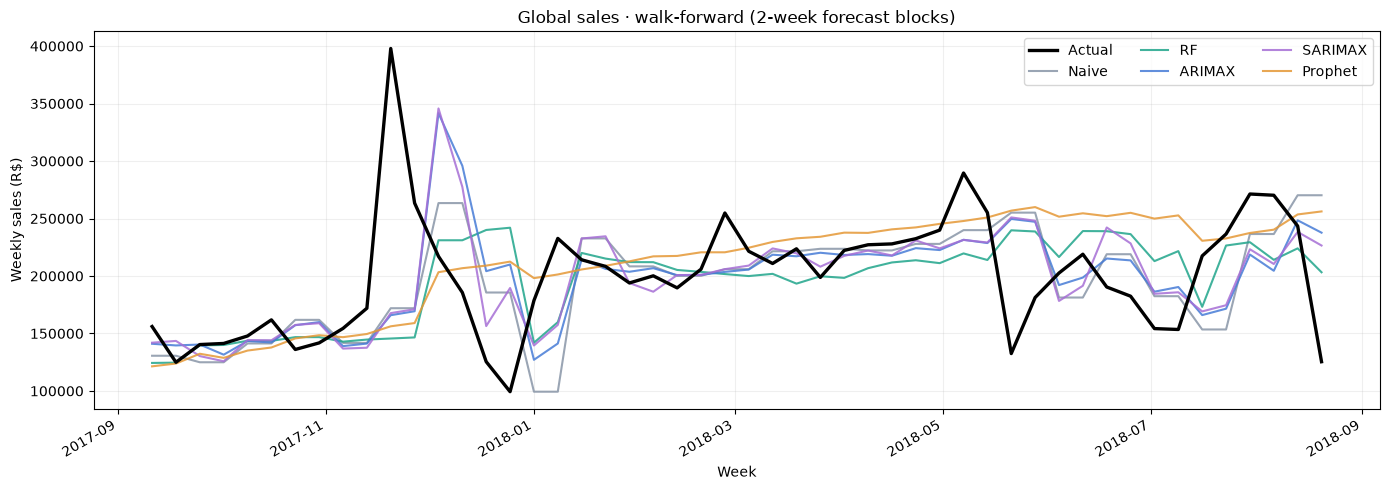

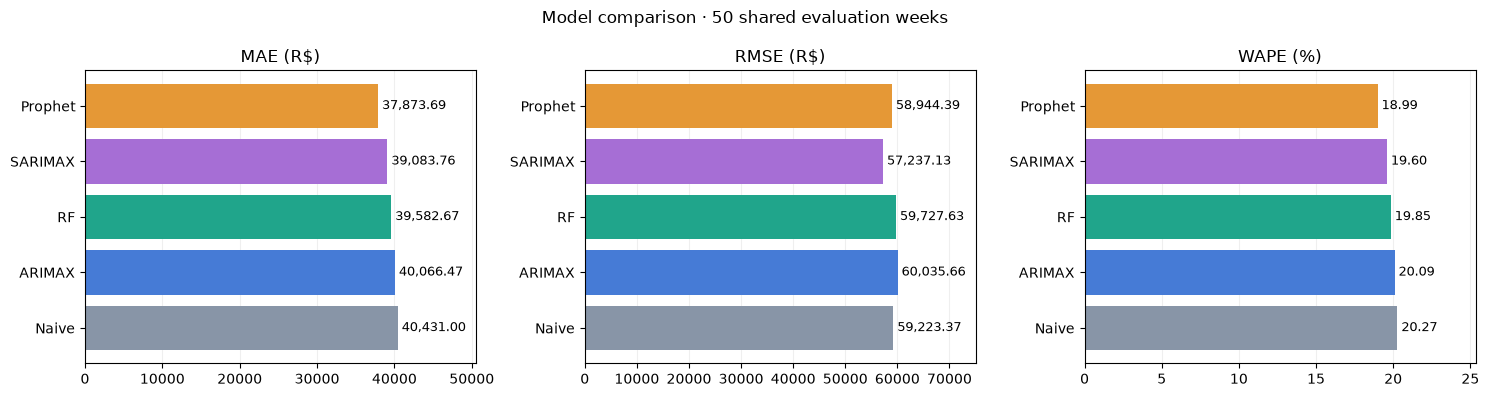

In [10]:
colors = {'Naive': '#8895a7', 'RF': '#20a58b', 'ARIMAX': '#467bd6',
          'SARIMAX': '#a66ed5', 'Prophet': '#e59836'}
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(actual.index, actual, color='black', linewidth=2.4, label='Actual', zorder=5)
for name in models:
    ax.plot(wide.index, wide[name], label=name, color=colors[name], alpha=0.85)
ax.set(title=f'Global sales · walk-forward ({HORIZON_WEEKS}-week forecast blocks)',
       xlabel='Week', ylabel='Weekly sales (R$)')
ax.legend(ncol=3)
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, metrics.columns):
    values = metrics[metric]
    ax.barh(values.index, values, color=[colors[name] for name in values.index])
    ax.invert_yaxis()
    ax.set_title(metric)
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(x=0.25)
    for i, value in enumerate(values):
        if np.isfinite(value):
            ax.text(value, i, f' {value:,.2f}', va='center', fontsize=9)
fig.suptitle(f'Model comparison · {common.sum()} shared evaluation weeks')
plt.tight_layout()
plt.show()

Optional inspection: use `folds` for train/test dates, `predictions` for individual forecasts, and `diagnostics` for model warnings/failures.

Implementation references: [statsmodels SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html), [Prophet seasonality and regressors](https://facebook.github.io/prophet/docs/seasonality%2C_holiday_effects%2C_and_regressors.html), [Prophet non-daily data](https://facebook.github.io/prophet/docs/non-daily_data.html).
